# Translocation Assay: CZI or OME-Zarr

One analysis workflow for an HCS CZI, an OME-Zarr plate directory, or an OZX archive. Set `input_path` and `input_format` in the configuration cell, then use **Restart Kernel and Run All**. The layout, preview, tuning, segmentation, measurements, fitting, and exports are shared across inputs. `translocation_assay_io` handles container-specific reading; `translocation_plate_layout` and `translocation_assay_utils` provide the existing analysis helpers. The CZI CLI remains unchanged.

## 1. Import Libraries and Configure the Notebook

Select this workshop's local Pixi **default** kernel (`.pixi/envs/default/python.exe` on Windows). No packages are installed by the notebook. Inputs live under `data/translocation/`; outputs are separated by input name under `results/translocation/notebook_run/`. The setup cell discovers the workshop root from the current directory or its parents and checks the selected environment.

The workflow uses czitools/pylibCZIrw for CZI, Zarr for NGFF, and the same NumPy, pandas, SciPy, scikit-image, xarray, plotting, and widget dependencies for both. Progress uses `tqdm.auto`. On Windows, the kernel's native DLL directory is prioritized before numerical imports.

# Human U2OS cells cytoplasm–nucleus translocation

- 96-well plate, human osteosarcoma cells (U2OS)
- Cytoplasm to nucleus translocation of the Forkhead (FKHR-EGFP) fusion protein
- In proliferating cells, FKHR is localized in the cytoplasm (constantly moving into the nucleus but is transported out again by export proteins).
- Upon inhibition of nuclear export, FKHR accumulates in the nucleus
- Export is inhibited by blocking PI3 kinase / PKB with Wortmannin or LY294002.

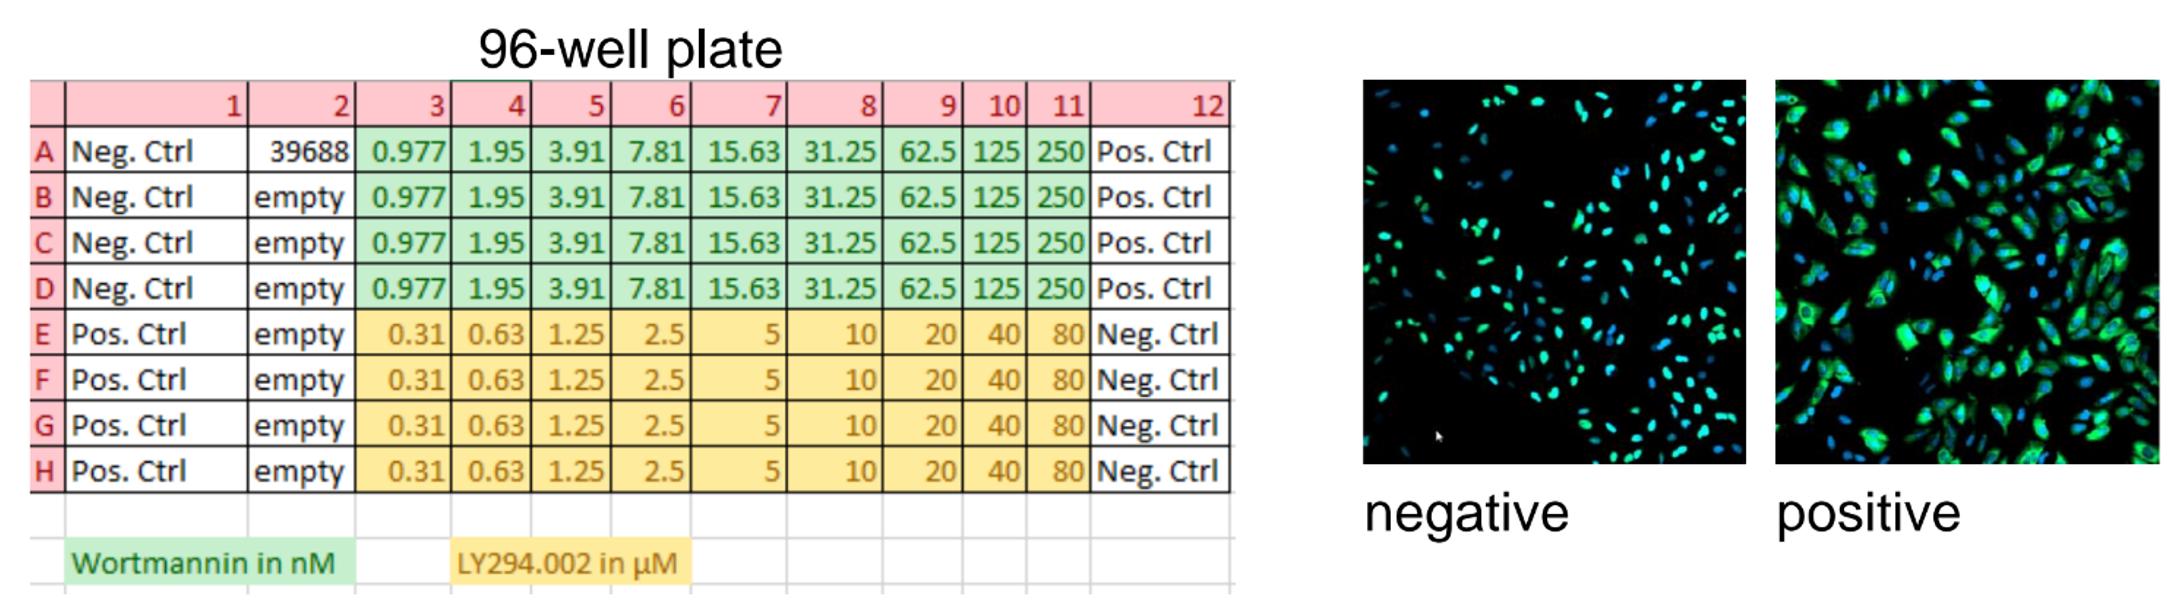

In [1]:
import json
import logging
import os
import platform
import sys
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path
from urllib.parse import quote

native_dll_dir = Path(sys.prefix) / "Library" / "bin"
if os.name == "nt" and native_dll_dir.is_dir():
    os.environ["PATH"] = str(native_dll_dir) + os.pathsep + os.environ.get("PATH", "")

current_dir = Path.cwd().resolve()
try:
    workshop_root = next(
        candidate
        for candidate in (current_dir, *current_dir.parents)
        if (candidate / "pixi.toml").is_file()
        and (candidate / "examples" / "translocation" / "translocation_assay.py").is_file()
    )
except StopIteration as exc:
    raise FileNotFoundError("Start the notebook from the workshop root or one of its subdirectories.") from exc
default_env = workshop_root / ".pixi" / "envs" / "default"
if Path(sys.prefix).resolve() != default_env.resolve():
    raise RuntimeError(f"Select the workshop Pixi default kernel from {default_env}.")
project_dir = workshop_root / "examples" / "translocation"
data_dir = workshop_root / "data" / "translocation"

for module_name in ("translocation_assay_io.py", "translocation_plate_layout.py", "translocation_assay_utils.py"):
    if not (project_dir / module_name).is_file():
        raise FileNotFoundError(f"Missing workshop assay module: {module_name}")
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
print(f"Kernel Python: {sys.executable}")
print(f"Workshop: {workshop_root}")
print(f"Project: {project_dir}")
print(f"Data: {data_dir}")

Kernel Python: F:\Pixi_Projects\zen_czi\smartmic_workshop\.pixi\envs\default\python.exe
Workshop: F:\Pixi_Projects\zen_czi\smartmic_workshop
Project: F:\Pixi_Projects\zen_czi\smartmic_workshop\examples\translocation
Data: F:\Pixi_Projects\zen_czi\smartmic_workshop\data\translocation


### Load the Analysis Libraries

Import numerical and project libraries after the environment paths have been configured. Inline plotting retains notebook figures; the shared exporter also closes its Matplotlib figures after saving them.

`display_scrollable_table()` accepts `max_height_px` (default `320`), `max_rows` (`None` for all rows, or a positive preview limit), `show_index` (default `False`), and `show_row_count` (default `False`). Scrolling remains enabled on both axes, and the original DataFrame is unchanged. For example, `display_scrollable_table(table, max_rows=10, show_row_count=True)` shows a counted preview; `display_scrollable_table(table, max_height_px=420, max_rows=None)` shows all rows in a taller scrolling area.

In [ ]:
import itables
import numpy as np
import pandas as pd
import translocation_assay_io as assay_io
import translocation_plate_layout as layouts
import xarray as xr
from IPython.display import HTML, IFrame, Image, display
from tqdm.auto import tqdm
from translocation_assay_utils import (
    THRESHOLD_METHODS,
    PlotBackend,
    ThresholdMethod,
    analyze_scenes,
    display_scrollable_table,
    write_analysis_outputs,
)

%matplotlib inline

itables.init_notebook_mode()

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 16)

## 2. Configure Input and Analysis

Choose exactly one ring-width unit: micrometers or pixels. The selected width, equivalent values in both units, threshold method, and segmentation settings are recorded in exports. EGFP index 0 is measured; DAPI index 1 defines nuclei.

`czi_reader_backend` applies only to CZI: `read_stacks` prepares genuinely lazy xarray/Dask arrays; `read_field` reads one well-local field at a time. OME-Zarr directories and OZX archives always use a read-only, full-resolution field reader, without extracting archives or loading the whole plate. Analysis processes one field at a time for every backend.

### Input Paths

Set `input_path` to the `.czi`, `.ome.zarr` directory, or `.ozx` archive. Examples for the supplied data appear in the configuration cell. `input_format = "auto"` detects the container; explicit `"czi"` or `"omezarr"` values must match it. These are local HCS plate inputs; single-image NGFF stores and remote URLs are not supported.

Keep inputs read-only under `data/translocation/`. Change `output_dir` when you need to retain multiple parameter runs for the same source. `segmentation_scene` uses stored CZI scene IDs for CZI, but sequential NGFF field IDs for OME-Zarr; the mapping table below identifies the selected source field.

In [3]:
input_path = data_dir / "transloc_gfp_dapi_0_2micron.czi"
# input_path = data_dir / "transloc_gfp_dapi_0_2micron_ngff_plate.ozx"
# input_path = data_dir / "transloc_gfp_dapi_0_2micron_ngff_plate_zarr3.ome.zarr"
input_format: assay_io.InputFormat = "auto"
czi_reader_backend: assay_io.ReaderBackend = "read_stacks"
output_dir = workshop_root / "results" / "translocation" / "notebook_run" / input_path.stem

ring_width_um: float | None = 2.0
ring_width_px: float | None = None
min_nucleus_area_px = 40
min_nucleus_distance_px = 8
threshold_method: ThresholdMethod = "otsu"
ratio_threshold = 2.0
plot_backend: PlotBackend = "seaborn"
segmentation_scene: int | None = 6
channel_indices = {"EGFP": 0, "DAPI": 1}

print(f"Input: {input_path} (format: {input_format})")
print(f"Outputs: {output_dir}")
print(f"CZI reader preference: {czi_reader_backend}")
print(f"DAPI threshold method: {threshold_method}")

Input: F:\Pixi_Projects\zen_czi\smartmic_workshop\data\translocation\transloc_gfp_dapi_0_2micron.czi (format: auto)
Outputs: F:\Pixi_Projects\zen_czi\smartmic_workshop\results\translocation\notebook_run\transloc_gfp_dapi_0_2micron
CZI reader preference: read_stacks
DAPI threshold method: otsu


### Plate Layout

Select exactly one source in the next cell: set `plate_layout_path` to an Excel workbook, or set it to `None` and edit the manual definitions inside the `else` branch. The default workbook is `data_dir / "plate_layout_example.xlsx"`. A missing or invalid workbook raises an error; it never silently activates the manual layout, and the two sources are never merged.

This cell resolves `plate_layout` once and previews the assignments that analysis will actually use. Excel input is validated with `layouts.load_plate_layout()`; manual assignments are built with `layouts.build_plate_layout()`. Manual dose lists must match `DOSE_COLUMNS` in length. Special conditions are applied last, so A1 intentionally overrides its negative-control assignment. Empty control lists or an empty special-condition dictionary disable those assignments.

The read-only ITables preview embeds JavaScript for offline use, with scrolling but no search, pagination, sorting, or index. It does not edit the workbook or select the wells analyzed. After saving workbook changes or switching sources, rerun this cell and every downstream cell. Later, the scene-mapping step checks that all acquired CZI wells are covered without rereading the workbook.

In [4]:
plate_layout_path: Path | None = data_dir / "plate_layout_example.xlsx"

resolved_plate_layout_path = plate_layout_path.resolve() if plate_layout_path is not None else None
if resolved_plate_layout_path is not None:
    plate_layout = layouts.load_plate_layout(resolved_plate_layout_path)
    plate_layout_source = str(resolved_plate_layout_path)
else:
    DOSE_WO = [0.977, 1.95, 3.91, 7.81, 15.63, 31.25, 62.5, 125.0, 250.0]
    DOSE_LY = [0.31, 0.63, 1.25, 2.5, 5.0, 10.0, 20.0, 40.0, 80.0]
    WELLS_WO = ["A", "B", "C", "D"]
    WELLS_LY = ["E", "F", "G", "H"]
    DOSE_COLUMNS = ["3", "4", "5", "6", "7", "8", "9", "10", "11"]
    DOSE_SERIES = (
        ("Wortmannin", WELLS_WO, DOSE_WO, "nM"),
        ("LY294002", WELLS_LY, DOSE_LY, "uM"),
    )
    POSITIVE_CONTROL_WELLS = [f"{row}12" for row in WELLS_WO] + [f"{row}1" for row in WELLS_LY]
    NEGATIVE_CONTROL_WELLS = [f"{row}1" for row in WELLS_WO] + [f"{row}12" for row in WELLS_LY]
    SPECIAL_CONDITIONS = {"A1": "Special condition (39688; unit unspecified)"}
    plate_layout = layouts.build_plate_layout(
        dose_series=DOSE_SERIES,
        dose_columns=DOSE_COLUMNS,
        positive_control_wells=POSITIVE_CONTROL_WELLS,
        negative_control_wells=NEGATIVE_CONTROL_WELLS,
        special_conditions=SPECIAL_CONDITIONS,
    )
    plate_layout_source = "Manual notebook configuration"

layout_table = pd.DataFrame([{"Well": well, **assignment} for well, assignment in plate_layout.items()])
print(f"Plate layout: {plate_layout_source} ({len(plate_layout)} wells)")
itables.show(
    layout_table, showIndex=False, paging=False, ordering=False, connected=False,
    layout={"topStart": None, "topEnd": None, "bottomStart": None, "bottomEnd": None},
    scrollY="420px", scrollX=True,
)

Plate layout: F:\Pixi_Projects\zen_czi\smartmic_workshop\data\translocation\plate_layout_example.xlsx (96 wells)


## 3. Validate Settings and Load Plate Metadata

Settings and container selection are checked before analysis. CZI inputs run `czitools.hcs_check`, with its report shown in a scrollable panel. OME-Zarr inputs instead validate their declared plate wells, image paths, channels, full-resolution axes, and physical XY scaling.

NGFF accepts flat axes/transforms and nested NGFF 0.6 coordinate systems. Non-singleton extra dimensions, inconsistent channels or spacing, and missing physical scale are rejected rather than projected or guessed. Preparing metadata does not load plate pixels.

In [5]:
from contextlib import redirect_stdout
from html import escape
from io import StringIO

detected_input_format = assay_io.resolve_input_format(input_path, input_format)
if (ring_width_um is None) == (ring_width_px is None):
    raise ValueError("Specify exactly one ring width in micrometers or pixels.")
requested_ring_width = ring_width_um if ring_width_um is not None else ring_width_px
if requested_ring_width is None or not np.isfinite(requested_ring_width) or requested_ring_width <= 0:
    raise ValueError("Ring width must be finite and positive.")
for setting in (min_nucleus_area_px, min_nucleus_distance_px):
    if isinstance(setting, bool) or not isinstance(setting, int) or setting < 1:
        raise ValueError("Nucleus area and peak separation must be positive integers.")
if threshold_method not in THRESHOLD_METHODS:
    raise ValueError(f"Unsupported threshold method: {threshold_method}")
if not np.isfinite(ratio_threshold) or ratio_threshold <= 0:
    raise ValueError("The translocation ratio threshold must be finite and positive.")
if plot_backend not in ("seaborn", "plotly"):
    raise ValueError("Choose the seaborn or plotly plotting backend.")
if czi_reader_backend not in ("read_stacks", "read_field"):
    raise ValueError("Choose the read_stacks or read_field CZI reader backend.")
if segmentation_scene is not None and (
    isinstance(segmentation_scene, bool) or not isinstance(segmentation_scene, int) or segmentation_scene < 0
 ):
    raise ValueError("Preview scene must be a nonnegative integer or None.")

if detected_input_format == "czi":
    hcs_report = StringIO()
    try:
        with redirect_stdout(hcs_report):
            assay_io.run_hcs_check(input_path)
    finally:
        display(HTML(
            '<div style="max-height: 360px; max-width: 100%; overflow: auto;">'
            f'<pre style="margin: 0; white-space: pre;">{escape(hcs_report.getvalue())}</pre>'
            '</div>'
        ))
assay_input = assay_io.load_assay_input(input_path, input_format, czi_reader_backend)
metadata = assay_input.metadata
reader_backend = assay_input.reader_backend
if metadata.hcs is None:
    raise ValueError("The input must contain usable HCS plate metadata.")
output_dir.mkdir(parents=True, exist_ok=True)
print(f"Detected format: {assay_input.input_format}; reader: {reader_backend}")
print(f"HCS wells: {len(metadata.hcs.wells)}")

Detected format: czi; reader: read_stacks
HCS wells: 96


## 4. Map Fields to Wells and Treatments

All acquired wells must have assignments in the selected plate layout. Fields from the same well are pooled by the shared analysis.

For CZI, `SceneIndex` preserves the original zero-based stored scene index; `FieldPath` describes its HCS well and well-local field selector. For NGFF, indices follow declared plate-well / well-image order and `FieldPath` is the exact image-group path. NGFF indices must not be interpreted as original CZI scene IDs. The full table is exported as `field_mapping.csv`.

In [6]:
scene_wells = assay_input.scene_wells
unassigned_wells = sorted(set(scene_wells.values()) - set(plate_layout))
if unassigned_wells:
    raise ValueError(f"Acquired wells are missing from the layout: {unassigned_wells}")

scene_table = pd.DataFrame([
    {"SceneIndex": index, "Well": well, "FieldPath": assay_input.field_paths[index]}
    for index, well in sorted(scene_wells.items())
])
print(f"Plate layout: {plate_layout_source}")
print(f"Mapped fields: {len(scene_wells)}")
print(f"Field identifiers: {assay_input.field_index_meaning}")
display_scrollable_table(scene_table)
print("All acquired wells have treatment assignments.")
if segmentation_scene is not None and segmentation_scene not in scene_wells:
    raise ValueError(f"Requested preview scene {segmentation_scene} is not mapped to an HCS well.")

Plate layout: F:\Pixi_Projects\zen_czi\smartmic_workshop\data\translocation\plate_layout_example.xlsx
Mapped fields: 96
Field identifiers: Original zero-based stored CZI scene index


SceneIndex,Well,FieldPath
0,A1,A/1/field/0
1,A2,A/2/field/0
2,A3,A/3/field/0
3,A4,A/4/field/0
4,A5,A/5/field/0
5,A6,A/6/field/0
6,A7,A/7/field/0
7,A8,A/8/field/0
8,A9,A/9/field/0
9,A10,A/10/field/0


All acquired wells have treatment assignments.


## 5. Physical Scaling and Ring Width

The input adapter supplies validated `(Y, X)` pixel spacing in micrometers: CZI metadata scaling for CZI, or full-resolution NGFF dataset transforms with axis-unit conversion for OME-Zarr. Missing units or scale are not guessed.

Specify exactly one ring width. A physical width accounts for potentially unequal XY spacing; a pixel width is fixed in image pixels. Both equivalents are displayed and recorded. The segmentation and ring-generation algorithms are identical across input formats.

In [7]:
pixel_spacing_um = assay_input.pixel_spacing_um

if ring_width_um is not None:
    ring_width_equivalent_um_yx = (ring_width_um, ring_width_um)
    ring_width_equivalent_px_yx = tuple(ring_width_um / spacing for spacing in pixel_spacing_um)
    ring_width_label = (
        f"{ring_width_um:g} um "
        f"({ring_width_equivalent_px_yx[0]:g} px Y, {ring_width_equivalent_px_yx[1]:g} px X)"
    )
else:
    if ring_width_px is None:
        raise ValueError("Select a ring width before computing its equivalents.")
    ring_width_equivalent_px_yx = (ring_width_px, ring_width_px)
    ring_width_equivalent_um_yx = tuple(ring_width_px * spacing for spacing in pixel_spacing_um)
    ring_width_label = (
        f"{ring_width_px:g} px "
        f"({ring_width_equivalent_um_yx[0]:g} um Y, {ring_width_equivalent_um_yx[1]:g} um X)"
    )
display_scrollable_table(pd.DataFrame({
    "Axis": ["Y", "X"],
    "SpacingUmPerPixel": pixel_spacing_um,
    "RingEquivalentUm": ring_width_equivalent_um_yx,
    "RingEquivalentPx": ring_width_equivalent_px_yx,
}))
print(f"Ring label: {ring_width_label}")

Axis,SpacingUmPerPixel,RingEquivalentUm,RingEquivalentPx
Y,0.2,2.0,10.0
X,0.2,2.0,10.0


Ring label: 2 um (10 px Y, 10 px X)


## 6. Verify Channels and Preview One Field

Stored channel labels must match the configured EGFP and DAPI indices. Their metadata colors are shown for verification. The format-neutral preview reader loads only the selected source field, then the existing Stackview channel preview and tuning controls use the same 2D channel planes.

Set `segmentation_scene` to a mapped field ID, or `None` to preview the first field. Previewing and tuning do not change the analysis settings automatically.

In [8]:
import translocation_assay_utils as assay_utils

if metadata.channelinfo is None:
    raise ValueError("Channel metadata are unavailable.")
channel_names = list(metadata.channelinfo.names)
for channel, index in channel_indices.items():
    if not 0 <= index < len(channel_names):
        raise ValueError(f"Channel index {index} for {channel} is unavailable: {channel_names}")
    if channel_names[index].strip().casefold() != channel.casefold():
        raise ValueError(f"Expected {channel} at index {index}; found {channel_names[index]}.")
display_scrollable_table(pd.DataFrame([
    {"Channel": channel, "Index": index, "StoredName": channel_names[index],
     "DisplayColor": metadata.channelinfo.colors[index]}
    for channel, index in channel_indices.items()
]))
example_scene = segmentation_scene if segmentation_scene is not None else min(scene_wells)
example_reader = assay_input.preview_reader
example_field = example_reader(example_scene)
example_channels = {
    channel: np.asarray(example_field.isel(C=channel_indices[channel]).squeeze(drop=True).values)
    for channel in ("EGFP", "DAPI")
}
if any(image.ndim != 2 for image in example_channels.values()):
    raise ValueError("The example preview requires 2D EGFP and DAPI planes.")
print(f"Example scene: {example_scene} (well {scene_wells[example_scene]})")
example_view = assay_utils.make_channel_preview(
    egfp=example_channels["EGFP"], dapi=example_channels["DAPI"],
)
display(example_view)

Channel,Index,StoredName,DisplayColor
EGFP,0,EGFP,#FF00FF5B
DAPI,1,DAPI,#FF00A1FF



  0% |                                                   | ETA:  --:--:-- 0 of 2


100% |###################################################| Time:  0:00:00 2 of 2

Example scene: 6 (well A7)


### Interactive Well and Field Tuning

The next cell starts with the well containing `segmentation_scene` (or the raw preview's first scene). Choose another acquired well from the dropdown and a field from its slider. Field labels are one-based within the well; the stored scene index is shown separately. A well with one acquired field has only one slider position.

The **Threshold** dropdown offers **Otsu**, **Li**, **Yen**, **Triangle**, **Isodata**, and **Mean** for DAPI primary-object segmentation, starting from the configured `threshold_method`. Each computes one global threshold per field using finite pixels; constant fields produce no nuclei. All methods share the same small-object removal, hole filling, and watershed splitting. The live summary shows the active method and threshold.

The sliders start from the configured minimum nucleus area, watershed peak spacing, ring width, and translocation-ratio threshold. **Peak spacing (px)** (`min_nucleus_distance_px`, previously labeled Separation) sets the minimum spacing between distance-transform peaks used as watershed seeds. It controls nucleus splitting, not a guaranteed edge-to-edge distance between primary objects and not a minimum gap between neighboring rings. Ring width sets the maximum outward expansion; a separate contact-removal step removes ring pixels touching differently labeled nuclei or rings. There is no configurable minimum ring-to-ring gap.

Ring units follow the active micrometer/pixel setting. Updates run when you release a slider. Only the displayed field is read, and parameter changes reuse its cached EGFP/DAPI planes; the same shared segmentation, ring construction, and measurement functions are used as in the full assay.

EGFP is green and DAPI is blue. White outlines mark nuclei and magenta outlines mark rings. Solid yellow fills the complete nucleus mask, including its boundary, for responders whose finite nucleus/ring ratio is at or above the selected cutoff. The toggles independently control these overlays. Changing the ratio cutoff changes classification, not the segmentation. The live summary reports nucleus count, valid ratios, fraction above the cutoff, and the field's selected DAPI threshold.

This is an exploratory preview, not a per-field analysis configuration: slider values and the selected threshold method carry over when switching fields but do not modify the analysis settings, `results`, or exports. Inspect several representative fields, then enter chosen values, including `threshold_method`, in **Input Paths and Analysis Settings** and rerun the analysis and export cells. Supported setting values are `"otsu"`, `"li"`, `"yen"`, `"triangle"`, `"isodata"`, and `"mean"`; Otsu remains the default.

In [9]:
if example_reader is None:
    raise ValueError("Run the channel-preview cell to prepare the field reader.")

tuning_well = scene_wells[example_scene]
field_tuner = assay_utils.make_field_tuner(
    tuning_well,
    field_reader=example_reader,
    scene_wells=scene_wells,
    channel_indices=channel_indices,
    pixel_spacing_um=pixel_spacing_um,
    min_nucleus_area_px=min_nucleus_area_px,
    min_nucleus_distance_px=min_nucleus_distance_px,
    ring_width_um=ring_width_um,
    ring_width_px=ring_width_px,
    ratio_threshold=ratio_threshold,
    threshold_method=threshold_method,
)
display(field_tuner)


  0% |                                                   | ETA:  --:--:-- 0 of 2


100% |###################################################| Time:  0:00:00 2 of 2

## 8. Prepare the Analysis Reader

The shared input adapter returns either lazy CZI scene arrays or an on-demand field-reader callback. CZI honors `czi_reader_backend`; NGFF directories and OZX archives reopen their source read-only for each full-resolution field and close the handle after reading it.

The downstream `analyze_scenes()` call is unchanged. This preparation step does not read all field pixels; the following analysis loop loads and processes one field at a time.

In [10]:
preparation_label = "Prepare lazy scenes" if reader_backend == "read_stacks" else "Prepare field reader"
with tqdm(total=None, desc=preparation_label, unit="field") as preparation_progress:
    scene_arrays, dimensions, scene_count, field_reader = assay_input.prepare_scene_inputs()
    if scene_arrays is not None and not all(isinstance(scene, xr.DataArray) for scene in scene_arrays):
        raise TypeError("Expected xarray scene arrays.")
    preparation_progress.reset(total=scene_count)
    preparation_progress.update(scene_count)
print(f"Prepared {scene_count} fields with {reader_backend}; axes: {dimensions}")
if scene_arrays is not None:
    print(f"First scene sizes: {dict(scene_arrays[0].sizes)}")
else:
    print("Analysis will load one field at a time from the source mapping.")


Prepare lazy scenes: 0field [00:00, ?field/s]


Prepare lazy scenes:   0%|          | 0/96 [00:00<?, ?field/s]


Prepare lazy scenes: 100%|██████████| 96/96 [00:00<00:00, 95778.59field/s]

Prepared 96 fields with read_stacks; axes: ['H', 'T', 'C', 'Z', 'Y', 'X']
First scene sizes: {'H': 1, 'T': 1, 'C': 2, 'Z': 1, 'Y': 640, 'X': 640}


## 8. Analyze Fields and Measure Translocation

`analyze_scenes()` uses the same parameters and utilities as the script for either reader backend:

1. Compute one lazy scene (`read_stacks`) or read one complete field by well/local index (`read_field`), then extract matching EGFP/DAPI planes.
2. Segment DAPI with the configured global `threshold_method` (Otsu by default), small-object removal, hole filling, distance peaks, and watershed splitting. Each field gets its own threshold; the chosen method is recorded in exported parameters and provenance.
3. Assign surrounding pixels to the nearest nucleus within the ring distance, excluding nuclei and contacts with other labels.
4. Measure raw mean EGFP in nuclei and rings. The nucleus/ring ratio is invalid when the ring is empty or its mean is nonpositive.
5. Pool all fields belonging to each well, then aggregate finite ratios by well and drug/dose. A ratio **greater than or equal to** the threshold counts as above threshold.
6. Fit an increasing bounded four-parameter Hill response to pooled valid-cell fractions, not a replicate-weighted well average.

At least four finite positive doses and variable responses are required for fitting. There is no control normalization, background subtraction, or confidence interval estimation. Rings are local cytoplasmic proxies and may be truncated by crowding/field edges; they are not whole-cell masks. The callback updates the second progress bar using completed-field counts without per-field log spam. Stored scene IDs remain unchanged in object records and preview selection.

In [11]:
# Process each field with the same analysis pipeline for either reader backend.
with tqdm(total=scene_count, desc="Process fields", unit="field") as processing_progress:
    def update_processing_progress(completed: int, total: int) -> None:
        """Update tqdm from cumulative field counts, not stored scene IDs."""
        processing_progress.total = total
        processing_progress.update(completed - processing_progress.n)

    results = analyze_scenes(
        metadata=metadata,
        scene_arrays=scene_arrays,
        scene_wells=scene_wells,
        channel_indices=channel_indices,
        pixel_spacing_um=pixel_spacing_um,
        dimensions=dimensions,
        min_nucleus_area_px=min_nucleus_area_px,
        min_nucleus_distance_px=min_nucleus_distance_px,
        threshold_method=threshold_method,
        ratio_threshold=ratio_threshold,
        ring_width_um=ring_width_um,
        ring_width_px=ring_width_px,
        plate_layout=plate_layout,
        segmentation_scene=segmentation_scene,
        progress_callback=update_processing_progress,
        field_reader=field_reader,
    )
print(f"Processed {results.fields_processed} fields; detected {len(results.cell_table):,} nuclei.")


Process fields:   0%|          | 0/96 [00:00<?, ?field/s]


Process fields:   1%|          | 1/96 [00:00<00:31,  2.99field/s]


Process fields:   3%|▎         | 3/96 [00:00<00:14,  6.22field/s]


Process fields:   5%|▌         | 5/96 [00:00<00:11,  7.81field/s]


Process fields:   6%|▋         | 6/96 [00:00<00:10,  8.30field/s]


Process fields:   7%|▋         | 7/96 [00:01<00:12,  7.26field/s]

... (42 outputs left out)


Process fields:  97%|█████████▋| 93/96 [00:09<00:00, 10.52field/s]


Process fields:  99%|█████████▉| 95/96 [00:09<00:00, 10.59field/s]


Process fields: 100%|██████████| 96/96 [00:09<00:00,  9.94field/s]

Processed 96 fields; detected 17,288 nuclei.


## 10. Export Measurements and Provenance

The existing export helper writes cell measurements, well and dose summaries, EC50 fits, heatmaps, and the segmentation preview. `field_mapping.csv` connects analysis field IDs to wells and source image selectors. The selected Excel layout is copied to `plate_layout_used.csv`.

`analysis_parameters.json` and `notebook_provenance.json` record the input path, detected/requested format, actual reader backend, field-index meaning, mapping filename, NGFF resolution level (0), and analysis/layout choices. Provenance also records the Pixi environment, interpreter, package versions, and UTC timestamp. Outputs are separated by input name; choose a fresh directory to preserve previous runs with different settings.

In [12]:
scene_table.to_csv(output_dir / "field_mapping.csv", index=False)
input_parameters = {
    "InputPath": str(assay_input.path),
    "InputFormat": assay_input.input_format,
    "InputFormatRequested": input_format,
    "ReaderBackend": reader_backend,
    "CziReaderBackendRequested": czi_reader_backend,
    "NgffResolutionLevel": 0 if assay_input.input_format == "omezarr" else None,
    "FieldIndexMeaning": assay_input.field_index_meaning,
    "FieldMappingFile": "field_mapping.csv",
}
parameters = {
    **input_parameters,
    "Channels": {channel: channel_names[index] for channel, index in channel_indices.items()},
    "ChannelIndices": channel_indices,
    "PixelSpacingUmYX": list(pixel_spacing_um),
    "RingWidthUm": ring_width_um,
    "RingWidthPx": ring_width_px,
    "RingWidthEquivalentUmYX": list(ring_width_equivalent_um_yx),
    "RingWidthEquivalentPxYX": list(ring_width_equivalent_px_yx),
    "RingWidthLabel": ring_width_label,
    "MinNucleusAreaPx": min_nucleus_area_px,
    "MinNucleusDistancePx": min_nucleus_distance_px,
    "DapiThresholdMethod": threshold_method,
    "TranslocationRatioThreshold": ratio_threshold,
    "PlotBackend": plot_backend,
    "PlateLayoutSource": plate_layout_source,
    "SegmentationSceneRequested": segmentation_scene,
    "SegmentationSceneShown": results.segmentation_example[4] if results.segmentation_example is not None else None,
    "FieldsProcessed": results.fields_processed,
    "ObjectsDetected": len(results.cell_table),
}
if assay_input.input_format == "czi":
    parameters["InputCzi"] = str(assay_input.path)
else:
    parameters["InputOmeZarr"] = str(assay_input.path)
if resolved_plate_layout_path is not None:
    parameters["PlateLayoutFile"] = str(resolved_plate_layout_path)
    parameters["PlateLayoutSnapshot"] = "plate_layout_used.csv"
    layout_table.to_csv(output_dir / "plate_layout_used.csv", index=False)
write_analysis_outputs(results, output_dir, parameters, plot_backend)

package_names = [
    "czitools", "pylibCZIrw", "zarr", "numpy", "pandas", "scipy", "scikit-image",
    "xarray", "dask", "matplotlib", "seaborn", "plotly", "microfilm", "rich", "ipykernel", "openpyxl",
]
provenance = {
    **input_parameters,
    "ExportedAtUtc": datetime.now(UTC).isoformat(),
    "PixiEnvironment": "default",
    "PythonExecutable": sys.executable,
    "PythonVersion": platform.python_version(),
    "Platform": platform.platform(),
    "Packages": {name: version(name) for name in package_names},
    "DapiThresholdMethod": threshold_method,
    "PlateLayoutSource": plate_layout_source,
    "PlateLayoutFile": str(resolved_plate_layout_path) if resolved_plate_layout_path is not None else None,
    "PlateLayout": json.loads(layout_table.to_json(orient="records")),
}
(output_dir / "notebook_provenance.json").write_text(
    json.dumps(provenance, indent=2, allow_nan=False), encoding="utf-8",
)
print(f"Exported to {output_dir}")
display_scrollable_table(pd.DataFrame([
    {"File": path.name, "Bytes": path.stat().st_size}
    for path in sorted(output_dir.iterdir()) if path.is_file()
]))

INFO: Writing result tables to F:\Pixi_Projects\zen_czi\smartmic_workshop\results\translocation\notebook_run\transloc_gfp_dapi_0_2micron


INFO: Writing plate heatmaps with seaborn


INFO: Writing example nucleus/ring segmentation plot


INFO: Writing dose-response plot


INFO: Detected 17288 nuclei across 96 wells


INFO: Wrote assay tables and plots to F:\Pixi_Projects\zen_czi\smartmic_workshop\results\translocation\notebook_run\transloc_gfp_dapi_0_2micron


INFO: Wortmannin EC50: 6.755 nM


INFO: LY294002 EC50: 2.736 uM


Exported to F:\Pixi_Projects\zen_czi\smartmic_workshop\results\translocation\notebook_run\transloc_gfp_dapi_0_2micron


File,Bytes
analysis_parameters.json,1486
cell_measurements.csv,1880644
dose_response_ec50.png,229993
dose_response_summary.csv,1675
ec50_results.csv,382
field_mapping.csv,1889
heatmap_number_of_objects.png,150811
heatmap_translocation_ratio.png,167402
notebook_provenance.json,28153
plate_layout_used.csv,6332


## 10. Display Tables, Segmentation Previews, and Generated Plots

The next cell previews object measurements from **A3** by default. Change `object_preview_well` to another well, or set it to `None` to preview the first objects across all wells in stored order. Independently, set `well_preview_row` to a plate row such as `"A"` or `"B"` to filter the well-summary preview; `None` removes this row filter. Row letters are matched exactly, ignoring surrounding whitespace and the setting's case.

Set `table_preview_rows` to the positive number of rows to display for object measurements, EC50 fits, and well summaries when `well_preview_row` is `None`. **Selecting a plate row shows every matching well in a scrollable table**, regardless of this limit, so a complete row on a 96-well plate displays all twelve wells. **Dose summaries always show every row in a scrollable table**, regardless of this limit. The output reports matching and total counts as well as the displayed row count. A selected well or plate row with no measurements is reported explicitly.

These are display-only settings: rerun just the next cell after changing them. They do not change segmentation, analysis, underlying summary tables, or exported CSVs. Object-well and well-summary-row selections are independent; dose and EC50 summaries remain plate-wide. Plate heatmaps show retained nucleus counts and median valid nucleus/ring ratios. Inspect spatial trends and low-count wells before interpreting dose curves.

The microscopy preview uses microfilm colors on black, with nucleus/ring boundaries on the right. Inspect multiple scenes for splitting errors, missed nuclei, crowding, and border truncation. Change `segmentation_scene` and rerun downstream cells to inspect a different field.

Dose curves use pooled valid-cell fractions above threshold. Normalized panels use fitted bottom/top values when a fit exists, not controls. EC50 is the half-amplitude dose of the fitted increasing response. Check fit status, tested dose range, and sensitivity to settings; nuclei from one well are not independent biological replicates.

Seaborn PNGs are embedded as bytes and remain visible in saved notebook outputs. Plotly HTML uses local IFrames: keep the exported HTML and `plotly.min.js` together, serve the notebook and exports under the same Jupyter root, and trust the notebook to view interactive content. Those HTML files are not embedded, so static notebook viewers may not render them. Default PNGs are the portable option. Missing optional plots are reported rather than displaying old files from unrelated backends.

In [13]:
object_preview_well: str | None = "A3"
well_preview_row: str | None = "B"
table_preview_rows = 10

if object_preview_well is not None:
    if not isinstance(object_preview_well, str) or not object_preview_well.strip():
        raise ValueError("Object preview well must be a nonempty well name or None.")
    object_preview_well = object_preview_well.strip().upper()
if well_preview_row is not None:
    if (
        not isinstance(well_preview_row, str)
        or not well_preview_row.strip().isascii()
        or not well_preview_row.strip().isalpha()
    ):
        raise ValueError("Well preview row must contain plate-row letters (for example A) or be None.")
    well_preview_row = well_preview_row.strip().upper()
if isinstance(table_preview_rows, bool) or not isinstance(table_preview_rows, int) or table_preview_rows < 1:
    raise ValueError("Table preview rows must be a positive integer.")

object_preview_table = results.cell_table
if object_preview_well is not None and not object_preview_table.empty:
    object_preview_table = object_preview_table.loc[object_preview_table["Well"].eq(object_preview_well)]
print(
    f"Object preview: {object_preview_well if object_preview_well is not None else 'all wells'}; "
    f"{len(object_preview_table):,} matching objects of {len(results.cell_table):,} total."
)

well_preview_table = results.well_table
if well_preview_row is not None and not well_preview_table.empty:
    well_preview_table = well_preview_table.loc[well_preview_table["Row"].eq(well_preview_row)]
print(
    f"Well summary preview: {well_preview_row if well_preview_row is not None else 'all rows'}; "
    f"{len(well_preview_table):,} matching wells of {len(results.well_table):,} total."
)

# Display summary tables for the analysis results
for table_name, table, max_rows in (
    ("Object measurements", object_preview_table, table_preview_rows),
    ("Well summaries", well_preview_table, None if well_preview_row is not None else table_preview_rows),
    ("Dose summaries", results.dose_table, None),
    ("EC50 fits", results.ec50_table, table_preview_rows),
):
    display(HTML(f"<h3>{table_name} ({len(table):,} rows)</h3>"))
    if table.empty:
        if table_name == "Object measurements" and object_preview_well is not None:
            print(f"No object measurements available for well {object_preview_well}.")
        elif table_name == "Well summaries" and well_preview_row is not None:
            print(f"No well summaries available for row {well_preview_row}.")
        else:
            print("No results available for this table.")
    else:
        display_scrollable_table(table, max_rows=max_rows, show_row_count=True)

# Display count of finite translocation ratios in the object measurements table
if not results.cell_table.empty:
    valid_ratio_count = int(np.isfinite(results.cell_table["TranslocationRatio"]).sum())
    print(f"Finite object ratios: {valid_ratio_count:,} / {len(results.cell_table):,}")

Object preview: A3; 242 matching objects of 17,288 total.
Well summary preview: B; 12 matching wells of 96 total.


Showing first 10 of 242 rows.


Well,SceneIndex,ObjectID,NucleusAreaPx,NucleusAreaUm2,RingAreaPx,MeanIntNuc,MeanIntRing,TranslocationRatio,DapiThreshold
A3,2,A3_S002_N0001,458,18.32,993,0.000000,0.022155,0.000000,58.640625
A3,2,A3_S002_N0002,305,12.20,950,18.862295,8.261053,2.283280,58.640625
A3,2,A3_S002_N0003,199,7.96,480,17.442211,36.987500,0.471570,58.640625
A3,2,A3_S002_N0004,347,13.88,758,43.806916,63.967018,0.684836,58.640625
A3,2,A3_S002_N0005,331,13.24,737,41.256798,48.208955,0.855791,58.640625
A3,2,A3_S002_N0006,294,11.76,783,17.244898,5.535121,3.115541,58.640625
A3,2,A3_S002_N0007,186,7.44,662,29.935484,35.543807,0.842214,58.640625
A3,2,A3_S002_N0008,247,9.88,862,15.417004,27.755220,0.555463,58.640625
A3,2,A3_S002_N0009,275,11.00,924,0.705455,3.046537,0.231560,58.640625
A3,2,A3_S002_N0010,292,11.68,926,39.708904,54.133909,0.733531,58.640625


Showing all 12 rows.


Well,WellPath,Row,Column,SceneIndices,FieldCount,NumberOfObjects,MeanIntNuc,MeanIntRing,MeanTranslocationRatio,MedianTranslocationRatio,FractionAboveThreshold,DapiThreshold,RingWidthUm,RingWidthPx,PlateID,ConditionID,Role,Drug,Dose,DoseUnit,Replicate,Notes,Control
B1,B/1,B,1,12,1,164,20.447268,28.912171,0.669373,0.571419,0.018519,34.171875,2.0,None,Plate01,negative_control,negative_control,Control,NaN,,2.0,,Negative
B2,B/2,B,2,13,1,203,29.566689,36.646719,0.712582,0.690602,0.000000,45.140625,2.0,None,Plate01,blank,blank,Unassigned,NaN,,NaN,,Blank or unassigned
B3,B/3,B,3,14,1,247,30.288458,36.600790,0.836106,0.680651,0.044898,44.296875,2.0,None,Plate01,Wortmannin_0.977_nM,treatment,Wortmannin,0.977,nM,2.0,,
B4,B/4,B,4,15,1,209,33.767712,35.619576,0.900762,0.763475,0.043689,28.265625,2.0,None,Plate01,Wortmannin_1.95_nM,treatment,Wortmannin,1.950,nM,2.0,,
B5,B/5,B,5,16,1,225,43.587602,32.304501,1.816085,1.149433,0.207207,40.078125,2.0,None,Plate01,Wortmannin_3.91_nM,treatment,Wortmannin,3.910,nM,2.0,,
B6,B/6,B,6,17,1,199,56.998404,23.139585,5.894375,2.324337,0.566327,30.796875,2.0,None,Plate01,Wortmannin_7.81_nM,treatment,Wortmannin,7.810,nM,2.0,,
B7,B/7,B,7,18,1,203,76.958293,11.354961,24.652610,7.628619,0.922280,30.796875,2.0,None,Plate01,Wortmannin_15.63_nM,treatment,Wortmannin,15.630,nM,2.0,,
B8,B/8,B,8,19,1,164,89.878042,9.574908,27.609721,11.364154,0.993464,51.046875,2.0,None,Plate01,Wortmannin_31.25_nM,treatment,Wortmannin,31.250,nM,2.0,,
B9,B/9,B,9,20,1,168,93.319092,9.197236,16.696988,12.711595,0.987654,40.078125,2.0,None,Plate01,Wortmannin_62.5_nM,treatment,Wortmannin,62.500,nM,2.0,,
B10,B/10,B,10,21,1,186,53.753370,3.928496,37.503835,20.789827,0.987805,34.171875,2.0,None,Plate01,Wortmannin_125_nM,treatment,Wortmannin,125.000,nM,2.0,,


Showing all 18 rows.


Drug,Dose,DoseUnit,NumberOfWells,WellsWithObjects,NumberOfCellsWithValidRatio,FractionAboveThreshold,MeanWellFractionAboveThreshold,MedianTranslocationRatio
Wortmannin,0.977,nM,4,4,881,0.066969,0.067800,0.754915
Wortmannin,1.950,nM,4,4,806,0.054591,0.055024,0.805699
Wortmannin,3.910,nM,4,4,809,0.182942,0.183017,1.116646
Wortmannin,7.810,nM,4,4,756,0.623016,0.626318,2.737168
Wortmannin,15.630,nM,4,4,702,0.943020,0.943859,9.051170
Wortmannin,31.250,nM,4,4,664,0.972892,0.973893,12.320729
Wortmannin,62.500,nM,4,4,606,0.975248,0.976971,14.545075
Wortmannin,125.000,nM,4,4,627,0.969697,0.969839,14.625128
Wortmannin,250.000,nM,4,4,586,0.952218,0.952157,13.546561
LY294002,0.310,uM,4,4,689,0.075472,0.071916,0.848630


Showing all 2 rows.


Drug,DoseUnit,EC50,Bottom,Top,HillSlope,RMSE,FitStatus,FitMessage
Wortmannin,nM,6.754523,0.058375,0.971474,3.55225,0.01101,success,Fit successful (bounded NumPy grid search).
LY294002,uM,2.736256,0.070945,0.982397,3.39925,0.01111,success,Fit successful (bounded NumPy grid search).


Finite object ratios: 16,601 / 17,288


### Generated Figures

The following display uses the writer's real output filenames. It skips segmentation/dose plots when the current result cannot produce them, even if stale files exist. Both count and ratio heatmaps are shown, followed by the segmentation preview and dose-response curves.

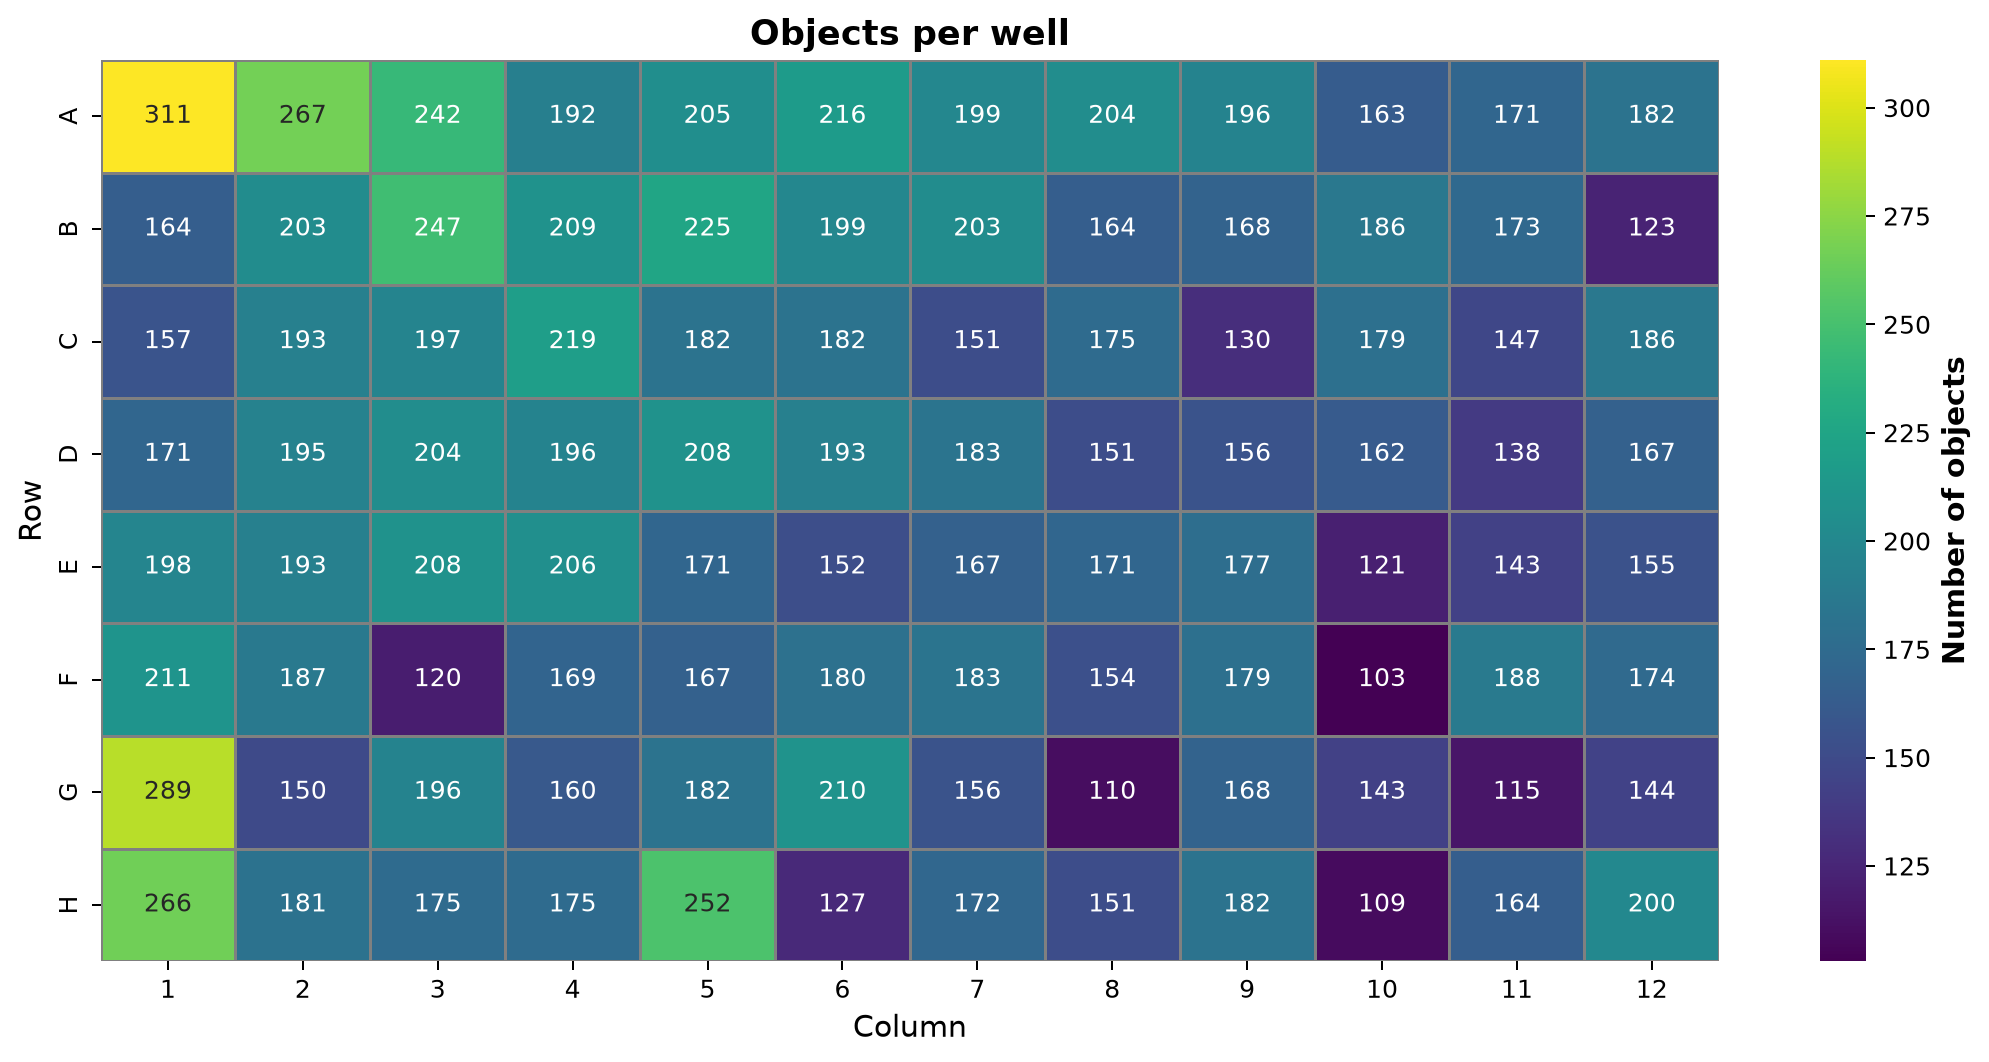

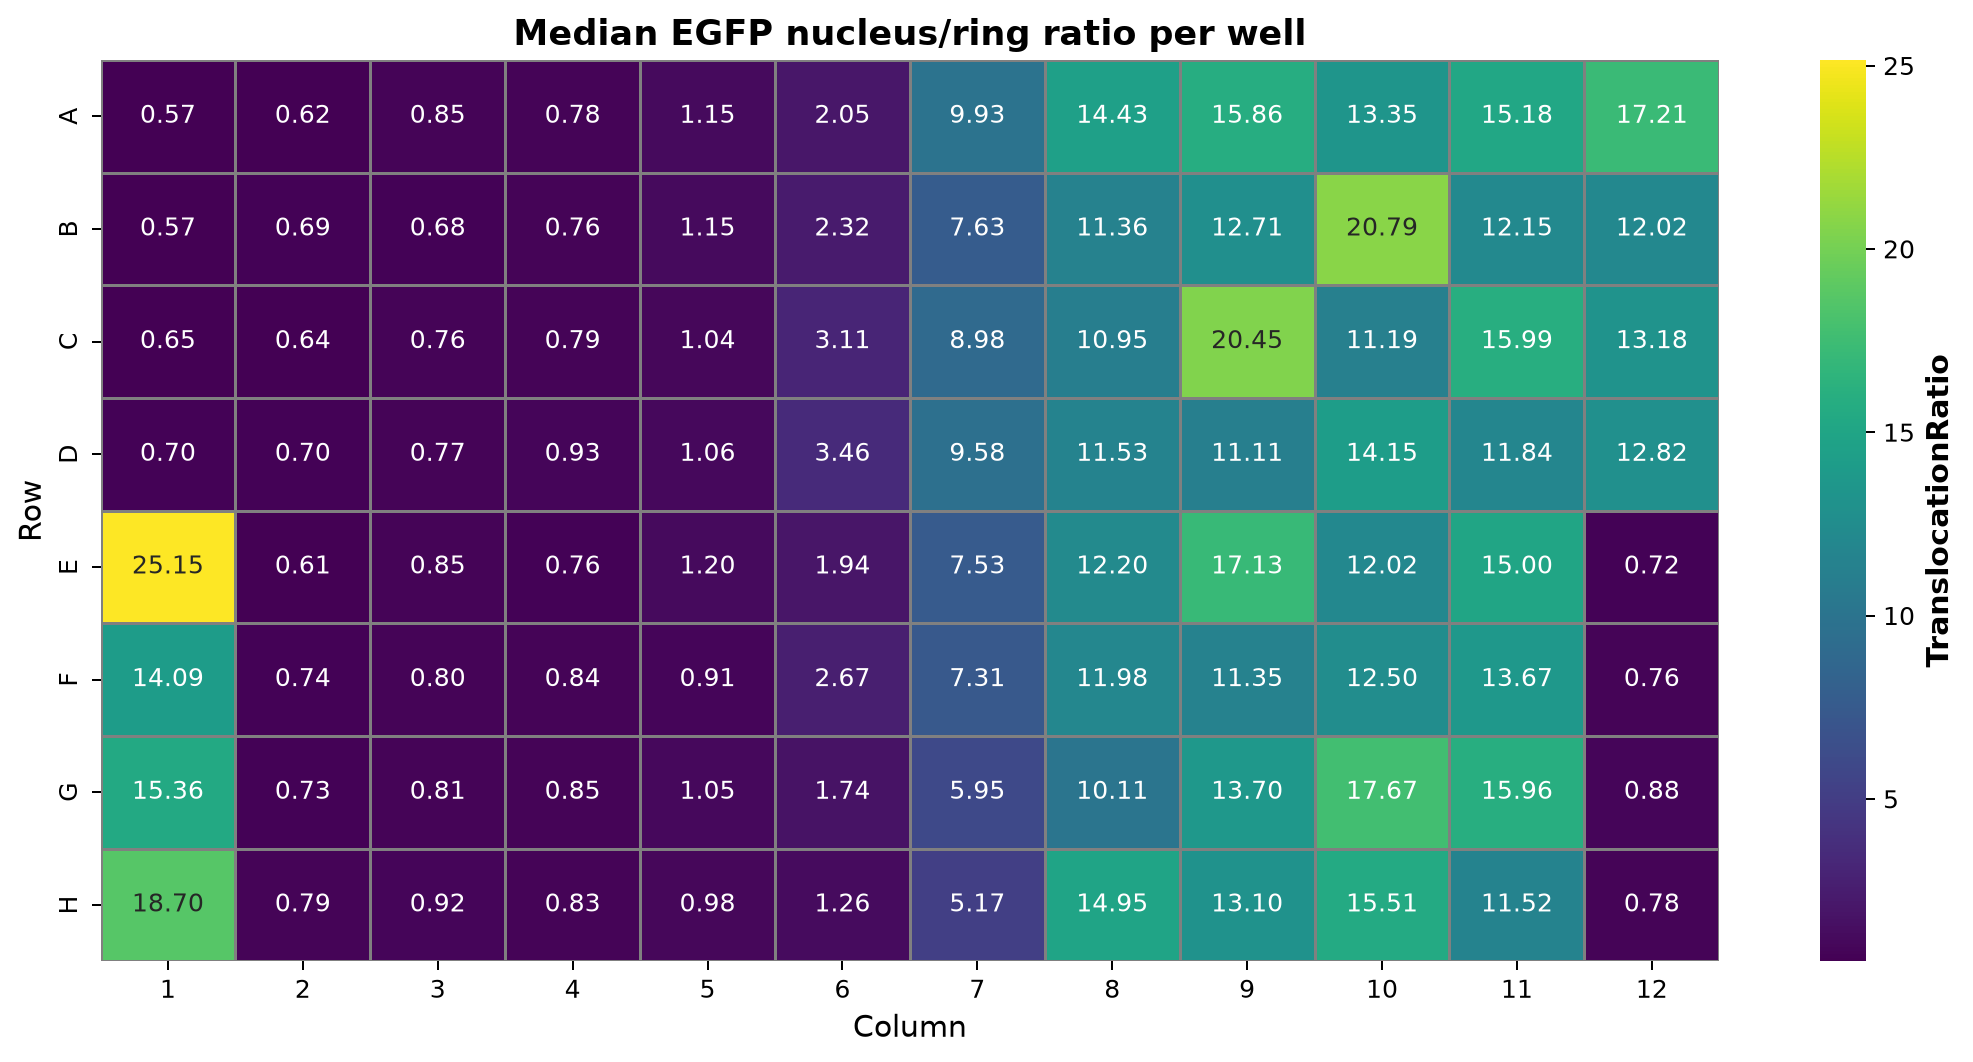

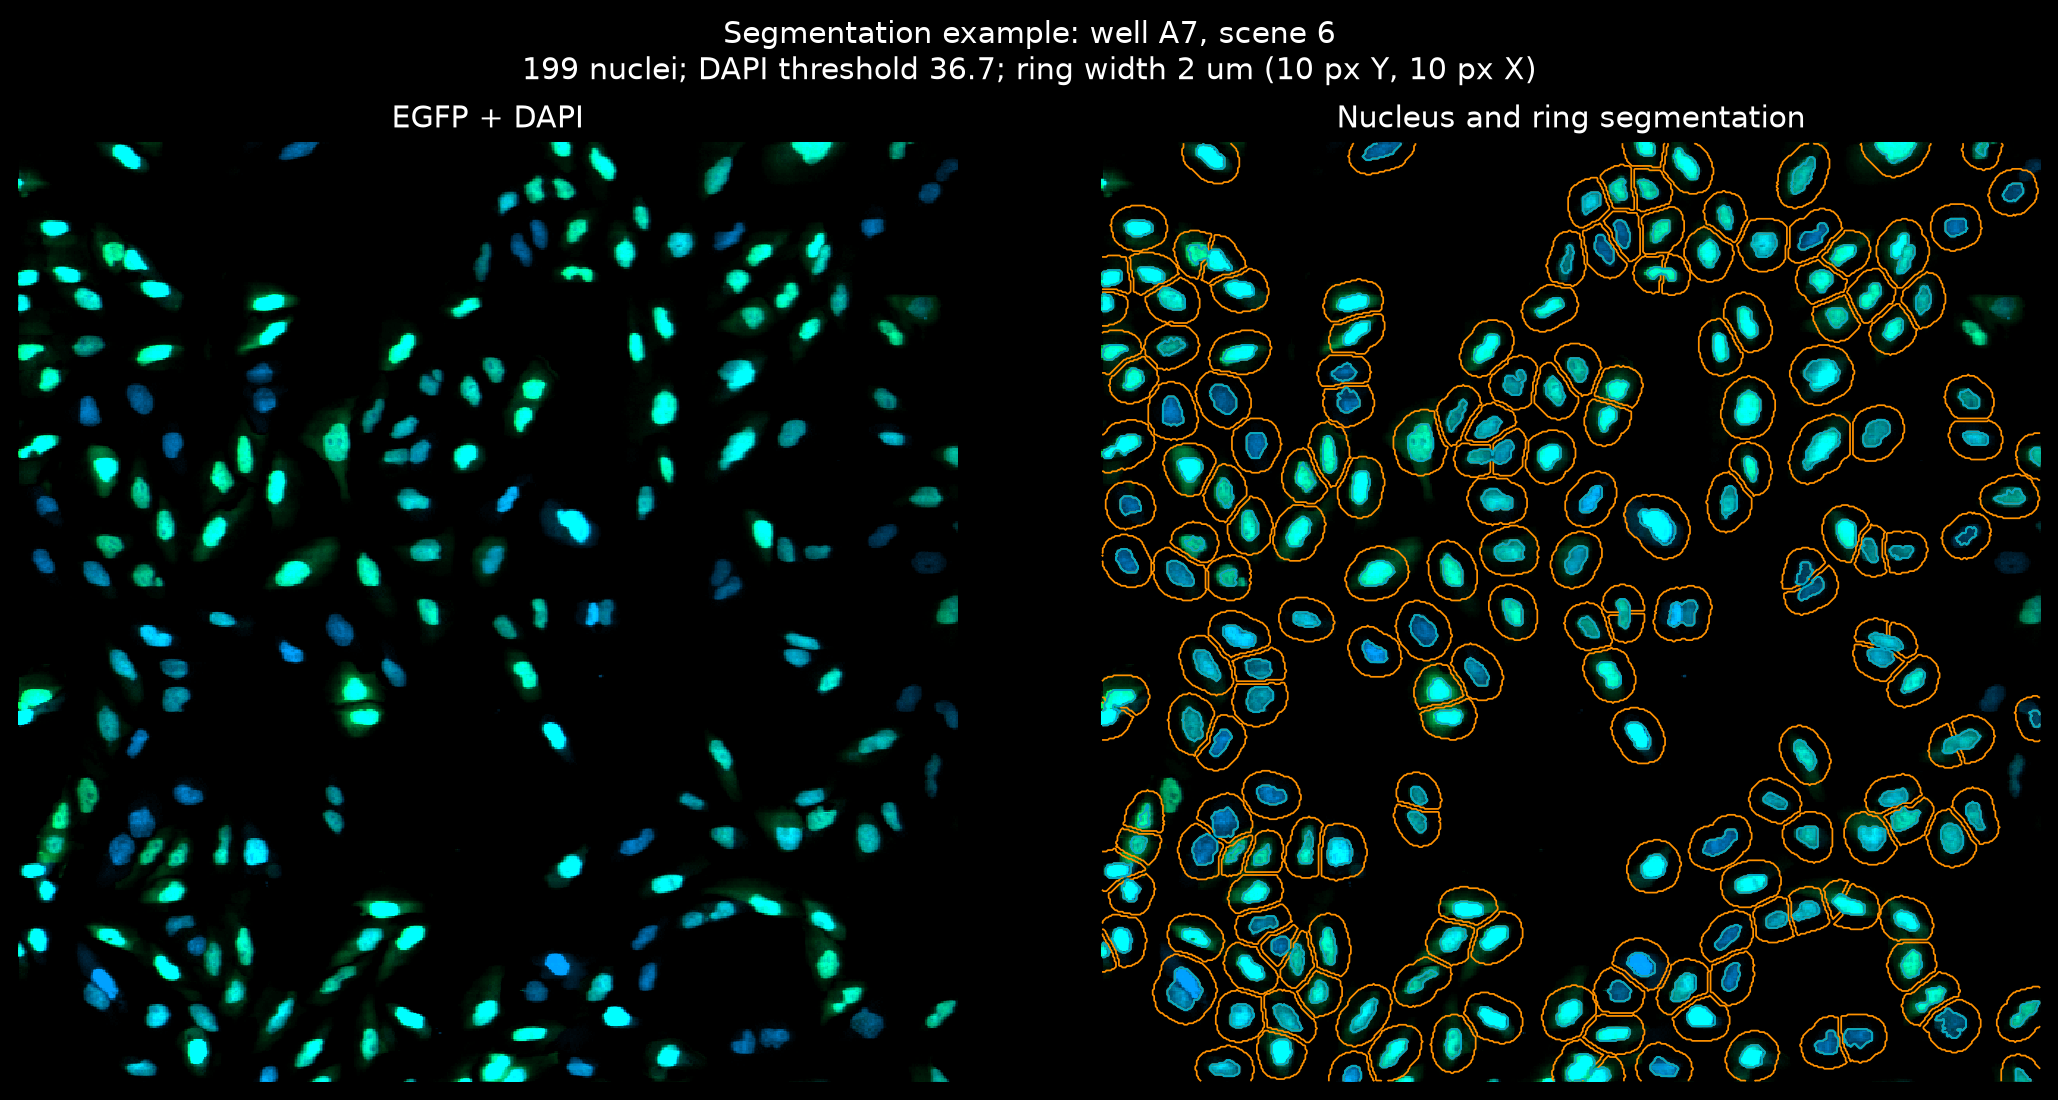

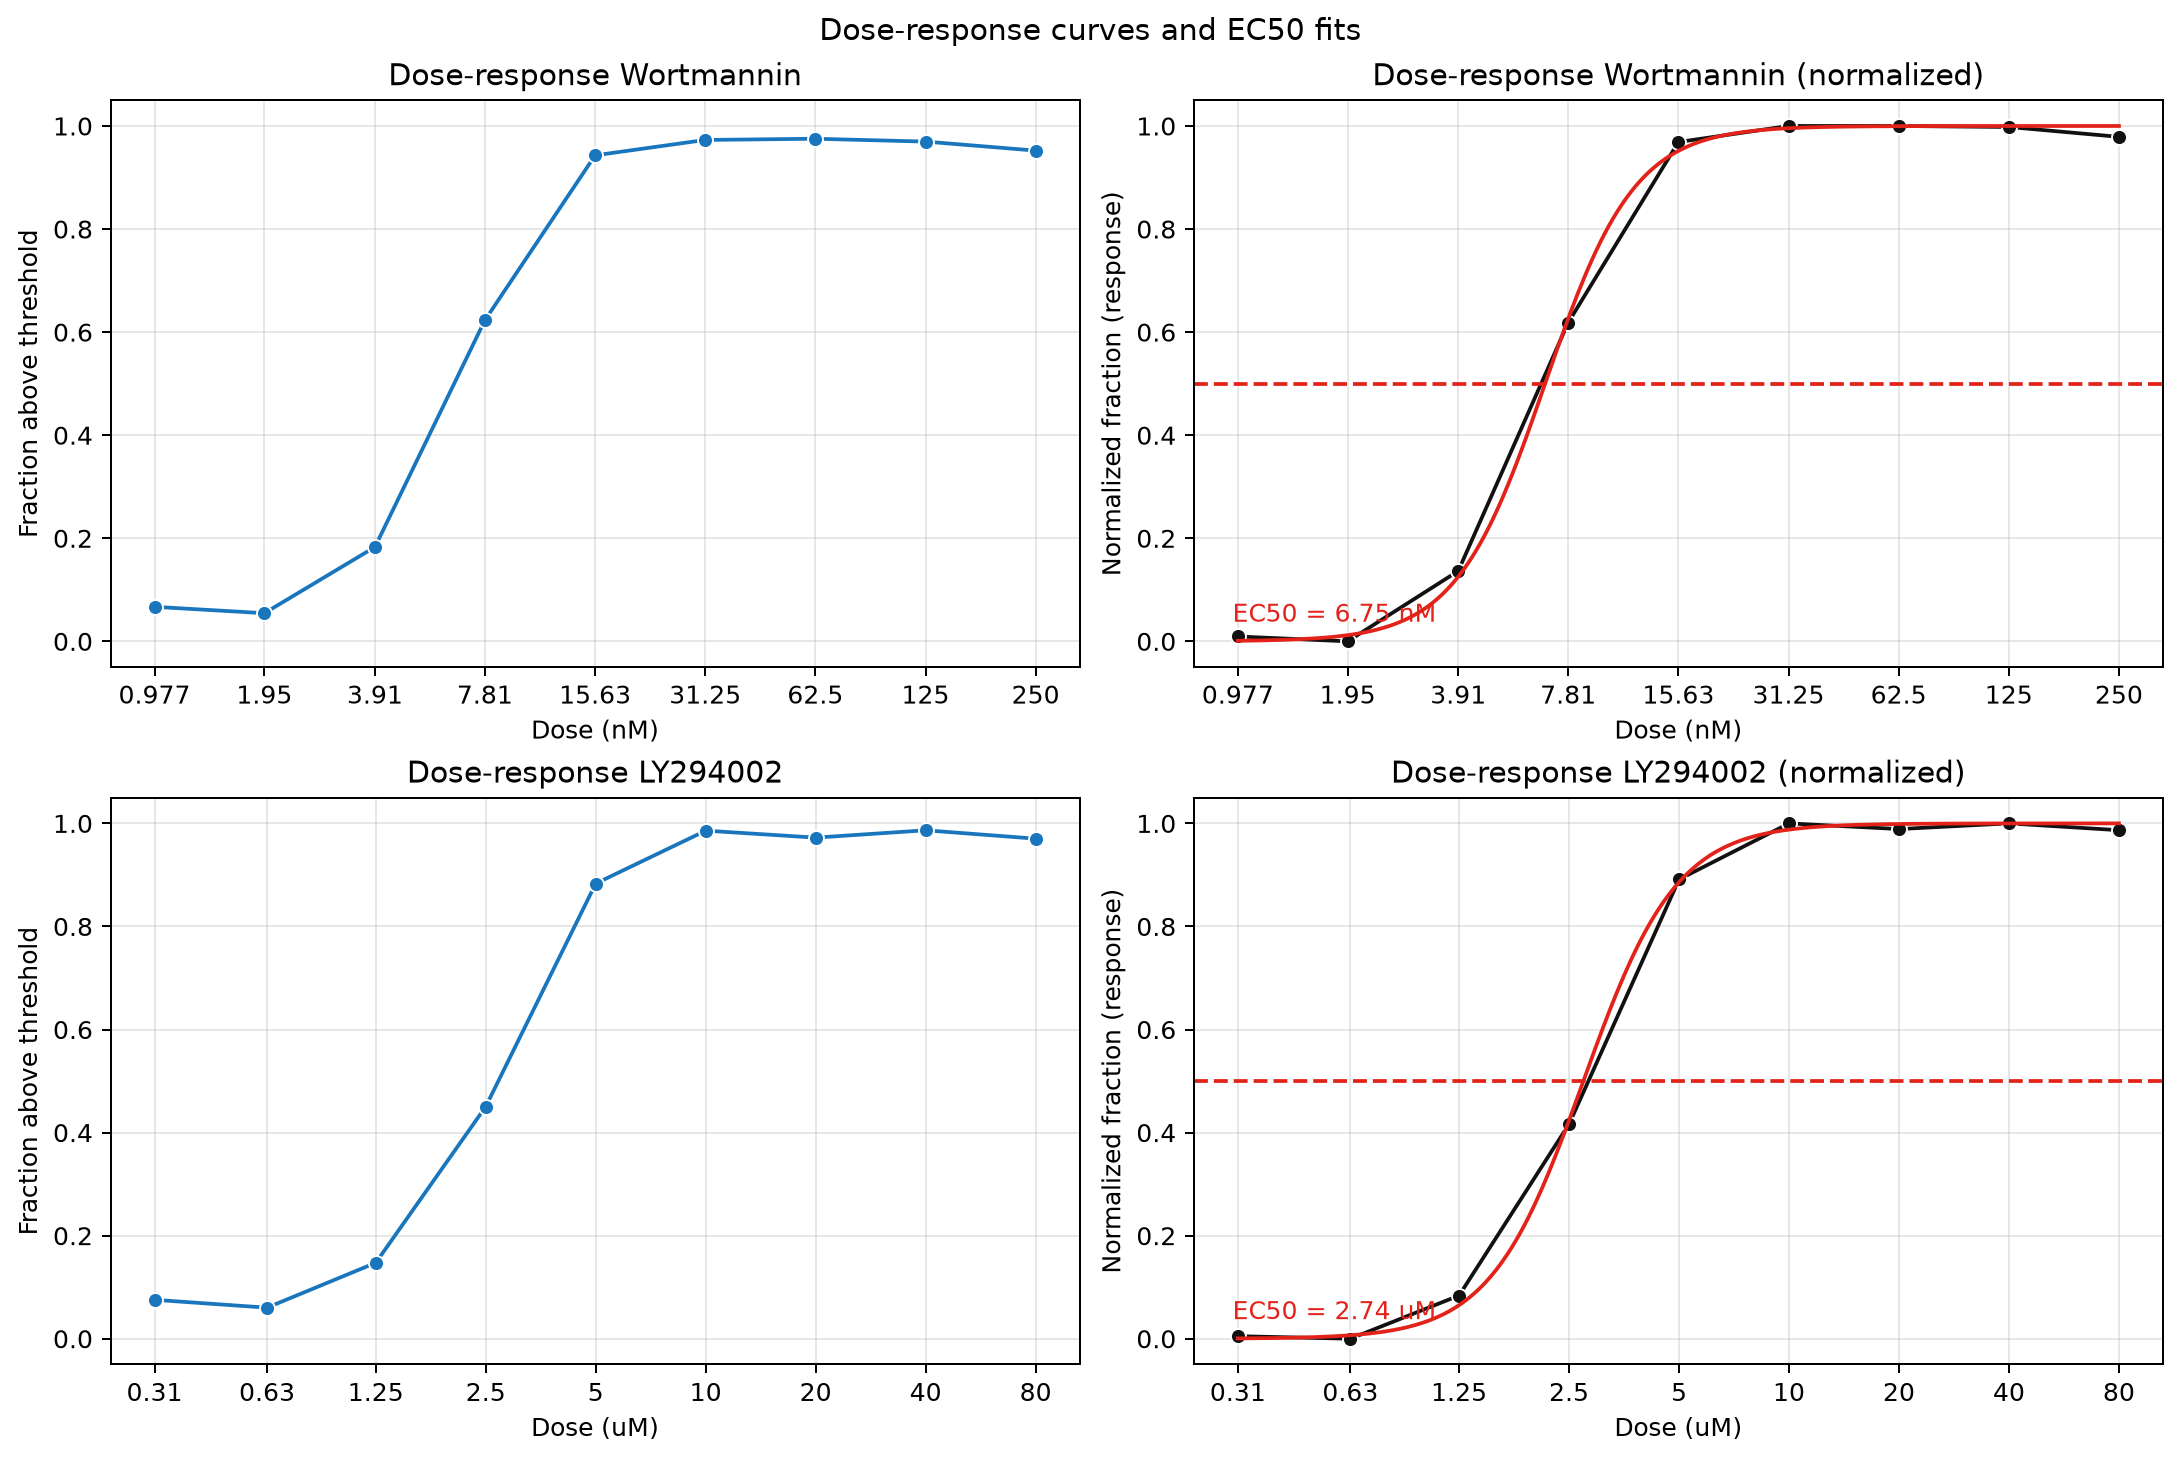

In [14]:
figure_specs = [
    ("heatmap_number_of_objects", "Nuclei per well", not results.well_table.empty),
    ("heatmap_translocation_ratio", "Median nucleus/ring ratio", not results.well_table.empty),
    ("segmentation_example", "Channel composite and segmentation", results.segmentation_example is not None),
    ("dose_response_ec50", "Dose-response curves and EC50", not results.dose_table.empty),
]
figure_extension = ".png" if plot_backend == "seaborn" else ".html"

# Display figures for the analysis results
for stem, title, available in figure_specs:
    display(HTML(f"<h3>{title}</h3>"))
    figure_path = output_dir / f"{stem}{figure_extension}"
    if not available:
        print("No figure available for the current results.")
    elif not figure_path.is_file():
        print(f"Figure was not exported: {figure_path.name}. Check export warnings.")
    elif plot_backend == "seaborn":
        display(Image(filename=str(figure_path), width=1100))
    else:
        relative_path = Path(os.path.relpath(figure_path, project_dir)).as_posix()
        display(IFrame(src=quote(relative_path, safe="/"), width="100%", height=900))
        print(f"Interactive file: {figure_path}")

## Reproducibility Checklist

- Select the local Pixi default kernel and restart/run all cells after changing input or configuration.
- Confirm the detected format, actual backend, channel identities, XY spacing, and field-to-well mapping.
- Keep NGFF field IDs distinct from original CZI scene indices when comparing segmentation previews.
- Verify the Excel/manual layout and controls; NGFF metadata supplies image identity, not treatment assignments.
- Preview threshold and ring choices, then explicitly transfer selected settings to the configuration cell.
- Keep input data unchanged and retain the output parameters, provenance, field mapping, layout snapshot, and measurements together.
- The CZI CLI still uses its existing CZI-only arguments; this notebook is the unified CZI/OME-Zarr/OZX workflow.